# Module 06 — Exercises — Solutions

These exercises rebuild the pieces of an automatic-differentiation system: finite differences,
forward mode with dual numbers, a reverse sweep by hand, topological sorting, the closures of a scalar
autograd engine, the matrix backward rules, a fused classification loss, a gradient checker, and a
planted bug to find. The mini-project trains a network with *your* engine. Only NumPy, `math` and
matplotlib (plus scikit-learn's `make_moons` for the project data) are allowed — no PyTorch, no JAX. The
concept guide (`README.md`) has every formula you need.

This notebook contains reference solutions and explanations for every exercise. Try the exercises yourself first — the learning happens in the struggle.

### Setup and self-check helpers
Run the next two cells first.

In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(0)
plt.rcParams["figure.figsize"] = (7, 4)

In [2]:
import hashlib as _hashlib
import numpy as _np

_results = {}

def _canon(value, decimals=3):
    """Canonical string form of an answer, so hashes are stable."""
    if isinstance(value, (bool, _np.bool_)):
        return "true" if value else "false"
    if isinstance(value, str):
        return " ".join(value.strip().lower().split())
    if isinstance(value, (int, _np.integer)):
        return str(int(value))
    if isinstance(value, (float, _np.floating)):
        s = f"{float(value):.{decimals}f}"
        return "0." + "0" * decimals if s in ("-0." + "0" * decimals, "-0") else s
    if isinstance(value, dict):
        return "{" + ",".join(f"{_canon(k, decimals)}:{_canon(v, decimals)}" for k, v in sorted(value.items(), key=lambda kv: str(kv[0]))) + "}"
    try:
        arr = _np.asarray(value)
        if arr.ndim == 0:
            return _canon(arr.item(), decimals)
        return "[" + ",".join(_canon(x, decimals) for x in arr.ravel().tolist()) + "]"
    except Exception:
        return str(value)

def sha_of(value, decimals=3):
    return _hashlib.sha256(_canon(value, decimals).encode()).hexdigest()[:16]

def check(name, condition, hint=""):
    """Record and print a pass/fail mark. Never raises, so the notebook keeps running."""
    try:
        ok = bool(condition)
    except Exception:
        ok = False
    _results[name] = ok
    print(("✅ " if ok else "❌ ") + name + ("" if ok or not hint else f"   — hint: {hint}"))
    return ok

def check_close(name, got, expected, tol=1e-6, hint=""):
    try:
        g = _np.asarray(got, dtype=float)
        e = _np.asarray(expected, dtype=float)
        ok = g.shape == e.shape and bool(_np.allclose(g, e, atol=tol, rtol=tol))
    except Exception:
        ok = False
    return check(name, ok, hint)

def check_hash(name, value, expected_sha, decimals=3, hint=""):
    """Compare an answer against a hidden expected value (only its hash is stored)."""
    try:
        ok = value is not None and sha_of(value, decimals) == expected_sha
    except Exception:
        ok = False
    return check(name, ok, hint)

def summary():
    n_ok = sum(1 for v in _results.values() if v)
    n = len(_results)
    print(f"\nScore: {n_ok}/{n} checks passed" + ("  🎉" if n and n_ok == n else ""))
    if n and n_ok < n:
        print("Not yet passing: " + ", ".join(k for k, v in _results.items() if not v))

## Exercise 1 — Finite differences and the best step size  `★☆☆`

Implement the two finite-difference estimators of $f'(x)$,

$$D^{+}_h f(x) = \frac{f(x+h) - f(x)}{h}, \qquad D^{c}_h f(x) = \frac{f(x+h) - f(x-h)}{2h},$$

as `forward_diff(f, x, h)` and `central_diff(f, x, h)` (both return a float), and `best_h(f, x, exact, hs, method)`,
which returns the entry of the NumPy array `hs` for which `method(f, x, h)` is closest to the known value `exact`.

Then answer (the checks hash your numbers): for $f(x) = x^3$ at $x = 2$ with $h = 0.1$, what do the two estimators return?

In [3]:
def forward_diff(f, x, h):
    return (f(x + h) - f(x)) / h

def central_diff(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def best_h(f, x, exact, hs, method):
    errs = [abs(method(f, x, h) - exact) for h in hs]
    return float(hs[int(np.argmin(errs))])

**Check your answer:**

In [4]:
cube = lambda t: t ** 3
try:
    f_est = forward_diff(cube, 2.0, 0.1)
    c_est = central_diff(cube, 2.0, 0.1)
except Exception:
    f_est = c_est = None
check_hash('forward estimate of (x^3)\' at 2 with h=0.1', f_est, '8326acae5fc56719')
check_hash('central estimate of (x^3)\' at 2 with h=0.1', c_est, '58023dc1612024dd')
try:
    hs = np.logspace(-12, -1, 23)
    bh_f = best_h(np.exp, 1.0, np.e, hs, forward_diff)
    bh_c = best_h(np.exp, 1.0, np.e, hs, central_diff)
except Exception:
    bh_f = bh_c = None
check('best forward-difference h for exp at 1 lies in [1e-9, 1e-7]', bh_f is not None and 1e-9 <= bh_f <= 1e-7)
check('best central-difference h for exp at 1 lies in [1e-7, 1e-4]', bh_c is not None and 1e-7 <= bh_c <= 1e-4)
try:
    sin_ok = bool(abs(central_diff(np.sin, 0.5, 1e-3) - np.cos(0.5)) < abs(forward_diff(np.sin, 0.5, 1e-3) - np.cos(0.5)))
except Exception:
    sin_ok = False
check('central beats forward at h=1e-3 for sin at 0.5', sin_ok)

✅ forward estimate of (x^3)' at 2 with h=0.1
✅ central estimate of (x^3)' at 2 with h=0.1
✅ best forward-difference h for exp at 1 lies in [1e-9, 1e-7]
✅ best central-difference h for exp at 1 lies in [1e-7, 1e-4]
✅ central beats forward at h=1e-3 for sin at 0.5


True

**Why this works**

The forward estimate carries an $O(h)$ error ($3xh + h^2 = 0.61$ here, giving 12.61) while the central one is
$O(h^2)$ ($h^2 = 0.01$, giving 12.01). The best step is where truncation error and round-off error ($\approx \varepsilon|f|/h$)
balance: about $\sqrt{\varepsilon} \approx 10^{-8}$ for forward differences and $\varepsilon^{1/3} \approx 10^{-5}$ for central
differences. Going smaller than that makes the estimate *worse*, which is the mistake people make when they
"improve" a gradient check by choosing $h = 10^{-12}$.

## Exercise 2 — Forward mode with dual numbers  `★☆☆`

Complete the `Dual` class: a value `val` carrying a tangent `dot`. Addition is given. Implement the product rule in
`__mul__`, the quotient rule in `__truediv__`, and `exp`, `sin`, `cos` via $g(a, \dot a) = (g(a), g'(a)\,\dot a)$.
Then implement `derivative(f, x)` which returns $f'(x)$ from **one** forward sweep (seed the input with tangent 1).

The hidden check asks for $\frac{d}{dx}\Big[\frac{x\,e^{x}\sin x}{x + 1}\Big]$ at $x = 2.1$.

In [5]:
class Dual:
    def __init__(self, val, dot=0.0):
        self.val, self.dot = float(val), float(dot)
    @staticmethod
    def lift(o):
        return o if isinstance(o, Dual) else Dual(o)
    def __add__(self, o):
        o = Dual.lift(o); return Dual(self.val + o.val, self.dot + o.dot)
    def __mul__(self, o):
        o = Dual.lift(o); return Dual(self.val * o.val, self.val * o.dot + self.dot * o.val)
    def __truediv__(self, o):
        o = Dual.lift(o); return Dual(self.val / o.val, (self.dot * o.val - self.val * o.dot) / o.val ** 2)
    def exp(self):
        e = math.exp(self.val); return Dual(e, e * self.dot)
    def sin(self):
        return Dual(math.sin(self.val), math.cos(self.val) * self.dot)
    def cos(self):
        return Dual(math.cos(self.val), -math.sin(self.val) * self.dot)
    __radd__, __rmul__ = __add__, __mul__

def derivative(f, x):
    return f(Dual(x, 1.0)).dot

**Check your answer:**

In [6]:
def _deriv(fn, at):
    # each derivative in its own try, so that one unfinished rule does not fail the other checks
    try:
        return derivative(fn, at)
    except Exception:
        return None
d_prod = _deriv(lambda x: x * x * x, 2.0)                              # 3x^2 = 12
d_quot = _deriv(lambda x: x.sin() / x, 2.0)                            # (x cos x - sin x)/x^2
d_exp = _deriv(lambda x: (x * 3.0).exp(), 0.5)                         # 3 e^{1.5}
d_hidden = _deriv(lambda x: x * x.exp() * x.sin() / (x + 1.0), 2.1)
check_close('product rule: d/dx x^3 at 2', d_prod, 12.0)
check_close('quotient rule: d/dx sin(x)/x at 2', d_quot, (2 * np.cos(2) - np.sin(2)) / 4)
check_close('chain through exp: d/dx e^(3x) at 0.5', d_exp, 3 * np.exp(1.5))
check_hash('hidden: derivative of x e^x sin x / (x+1) at 2.1', d_hidden, '41c8f0f3a88976b7')

✅ product rule: d/dx x^3 at 2
✅ quotient rule: d/dx sin(x)/x at 2
✅ chain through exp: d/dx e^(3x) at 0.5
✅ hidden: derivative of x e^x sin x / (x+1) at 2.1


True

**Why this works**

A dual number $(a, \dot a)$ behaves like $a + \dot a\,\epsilon$ with $\epsilon^2 = 0$, so multiplying two of them gives
$ab + (a\dot b + \dot a b)\epsilon$: the product rule falls out of the algebra. Every elementary function is
lifted by the chain rule, $g(a + \dot a\epsilon) = g(a) + g'(a)\dot a\,\epsilon$. Seeding the input with $\dot x = 1$ makes
every tangent equal to $\partial(\cdot)/\partial x$, so the output's tangent *is* $f'(x)$ — exact to rounding, with no step $h$.
The common wrong turn is forgetting to lift plain floats (`x + 1.0`) to duals with tangent 0.

## Exercise 3 — A reverse sweep by hand  `★☆☆`

Consider the graph with inputs $x_1 = 2$, $x_2 = 3$ and nodes

$$v_1 = x_1 x_2, \qquad v_2 = \exp(v_1 / 2), \qquad v_3 = v_1 + v_2\, x_1^2 .$$

Note that $x_1$ feeds two nodes ($v_1$ and the factor $x_1^2$) and $v_1$ feeds two nodes ($v_2$ and $v_3$ directly).
Fill in the adjoints $\bar v_3, \bar v_2, \bar v_1, \bar x_1, \bar x_2$ (as floats) by one reverse sweep,
summing contributions where a node has several children. Use the forward values already computed in the cell.

In [7]:
# forward values
v1 = 2.0 * 3.0          # x1 * x2 = 6
v2 = math.exp(v1 * 0.5)      # exp(v1/2) = e^3
v3 = v1 + v2 * 2.0 ** 2      # v1 + v2 * x1^2
# adjoints
bar_v3 = 1.0
bar_v2 = bar_v3 * 2.0 ** 2                 # 4
bar_v1 = bar_v3 * 1.0 + bar_v2 * v2 * 0.5  # direct + through exp
bar_x1 = bar_v1 * 3.0 + bar_v3 * v2 * 2 * 2.0   # x1 feeds v1 and the x1^2 factor
bar_x2 = bar_v1 * 2.0
adjoints = {"v3": bar_v3, "v2": bar_v2, "v1": bar_v1, "x1": bar_x1, "x2": bar_x2}

**Check your answer:**

In [8]:
def _get(k):
    try:
        v = adjoints[k]
        return None if v is None else float(v)
    except Exception:
        return None
check_close('adjoint of the output is 1', _get('v3'), 1.0)
check_close('adjoint of v2 is x1^2 = 4', _get('v2'), 4.0)
check_hash('hidden: adjoint of v1 (two contributions)', _get('v1'), 'a9b73619cee75fed')
check_hash('hidden: adjoint of x1 (two contributions)', _get('x1'), 'f66d0356f8092a4d')
check_hash('hidden: adjoint of x2', _get('x2'), '25da0bd92157d56a')

✅ adjoint of the output is 1
✅ adjoint of v2 is x1^2 = 4
✅ hidden: adjoint of v1 (two contributions)
✅ hidden: adjoint of x1 (two contributions)
✅ hidden: adjoint of x2


True

**Why this works**

Reverse topological order: $\bar v_3 = 1$. Then $\bar v_2 = \bar v_3 \cdot x_1^2 = 4$. The node $v_1$ has two children, so
$\bar v_1 = \bar v_3 \cdot 1 + \bar v_2 \cdot \tfrac12 e^{v_1/2} = 1 + 2 e^{3} \approx 41.17$. Likewise $x_1$ feeds $v_1$ and
$x_1^2$: $\bar x_1 = \bar v_1 x_2 + \bar v_3 \cdot 2 x_1 v_2 = 3\bar v_1 + 4 e^3 \approx 203.9$, and $\bar x_2 = \bar v_1 x_1 \approx 82.3$.
Forgetting one of the two contributions — the `=` instead of `+=` bug — is the single most common error in hand-written
backward passes, and it is exactly what the `+=` in an autograd engine protects against.

## Exercise 4 — Topological sort of a computational graph  `★★☆`

A graph is given as a list `nodes` and a dict `parents` mapping each node to a tuple of its parents (leaves have
no entry or an empty tuple). Implement `topo_sort(nodes, parents)` returning a list that contains every node exactly
once with each node *after* all of its parents (depth-first search with a visited set, as in the `Value.backward`
method), and `is_valid_topo(order, nodes, parents)` returning `True` iff `order` is such a list. Your function must
handle nodes that are reachable from several children (diamonds) and must not rely on the input order of `nodes`.

In [9]:
def topo_sort(nodes, parents):
    order, seen = [], set()
    def visit(n):
        if n in seen:
            return
        seen.add(n)
        for p in parents.get(n, ()):
            visit(p)
        order.append(n)
    for n in nodes:
        visit(n)
    return order

def is_valid_topo(order, nodes, parents):
    if sorted(order) != sorted(nodes) or len(order) != len(set(order)):
        return False
    position = {n: i for i, n in enumerate(order)}
    return all(position[p] < position[n] for n in nodes for p in parents.get(n, ()))

**Check your answer:**

In [10]:
chain_nodes = ["x", "a", "b", "L"]
chain_par = {"a": ("x",), "b": ("a",), "L": ("b",)}
diamond_nodes = ["L", "v3", "v2", "v1", "x1", "x2"]          # deliberately scrambled
diamond_par = {"v1": ("x1", "x2"), "v2": ("v1",), "v3": ("v1", "x1"), "L": ("v2", "v3")}
try:
    o1 = topo_sort(chain_nodes, chain_par)
    o2 = topo_sort(diamond_nodes, diamond_par)
except Exception:
    o1 = o2 = None
check('chain graph sorted', o1 == ["x", "a", "b", "L"])
def _valid(order, nodes, parents):
    if order is None or sorted(order) != sorted(nodes):
        return False
    pos = {n: i for i, n in enumerate(order)}
    return all(pos[p] < pos[n] for n in nodes for p in parents.get(n, ()))
check('diamond graph: every node once, parents first', _valid(o2, diamond_nodes, diamond_par))
try:
    ok_valid = is_valid_topo(["x1", "x2", "v1", "v2", "v3", "L"], diamond_nodes, diamond_par)
    ok_invalid = is_valid_topo(["x1", "v1", "x2", "v2", "v3", "L"], diamond_nodes, diamond_par)
    ok_dup = is_valid_topo(["x1", "x2", "v1", "v1", "v2", "L"], diamond_nodes, diamond_par)
except Exception:
    ok_valid = ok_invalid = ok_dup = None
check('is_valid_topo accepts a valid order', ok_valid is True)
check('is_valid_topo rejects a parent after its child', ok_invalid is False)
check('is_valid_topo rejects duplicates / missing nodes', ok_dup is False)
# random DAGs: generated so that parents always have smaller ids
ok_random = True
for trial in range(5):
    n = 12
    par = {i: tuple(int(p) for p in rng.choice(i, size=min(i, 2), replace=False)) for i in range(1, n)}
    nodes = list(rng.permutation(n))
    try:
        ok_random &= _valid(topo_sort(nodes, par), nodes, par)
    except Exception:
        ok_random = False
check('5 random DAGs sorted correctly', bool(ok_random))

✅ chain graph sorted
✅ diamond graph: every node once, parents first
✅ is_valid_topo accepts a valid order
✅ is_valid_topo rejects a parent after its child
✅ is_valid_topo rejects duplicates / missing nodes
✅ 5 random DAGs sorted correctly


True

**Why this works**

Depth-first search appends a node *after* recursing into its parents, so by the time a node is appended all its
ancestors are already in the list; the `seen` set guarantees that a node reachable along several paths (the diamond)
is appended once. Starting the search from every node in turn makes the result independent of the input order and
covers disconnected pieces. The validity test is the definition itself: a permutation of the nodes in which every
parent's position is smaller than its child's. `backward()` walks this order *in reverse* so that a node's gradient
is complete before it is handed to its parents.

## Exercise 5 — Complete the autograd engine  `★★☆`

The `Value` class below is complete except for the backward closures of `*`, `exp`, `log`, `tanh` and `relu`.
Each closure receives `g`, the gradient of the loss with respect to the node's output, and must **add** the correct
contribution to each parent's `.grad` (use the local derivative rules in the concept guide's table). Note that the
forward values `e` and `t` are already available to the closures.

The checks compare your gradients with closed forms and with central differences; the hidden check differentiates
a composite expression through all five operations.

In [11]:
class Value:
    def __init__(self, data, _parents=(), _op=""):
        self.data = float(data)
        self.grad = 0.0
        self._parents = _parents
        self._op = _op
        self._backward = lambda g: None

    def __repr__(self):
        return f"Value(data={self.data:.4g}, grad={self.grad:.4g})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def _backward(g):
            self.grad += g
            other.grad += g
        out._backward = _backward
        return out

    def __pow__(self, k):
        out = Value(self.data ** k, (self,), f"**{k}")
        def _backward(g):
            self.grad += k * self.data ** (k - 1) * g
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def _backward(g):
            self.grad += other.data * g
            other.grad += self.data * g
        out._backward = _backward
        return out

    def exp(self):
        e = math.exp(self.data)
        out = Value(e, (self,), "exp")
        def _backward(g):
            self.grad += e * g
        out._backward = _backward
        return out

    def log(self):
        out = Value(math.log(self.data), (self,), "log")
        def _backward(g):
            self.grad += g / self.data
        out._backward = _backward
        return out

    def tanh(self):
        t = math.tanh(self.data)
        out = Value(t, (self,), "tanh")
        def _backward(g):
            self.grad += (1.0 - t * t) * g
        out._backward = _backward
        return out

    def relu(self):
        out = Value(self.data if self.data > 0 else 0.0, (self,), "relu")
        def _backward(g):
            self.grad += (1.0 if self.data > 0 else 0.0) * g
        out._backward = _backward
        return out

    def __neg__(self):             return self * -1.0
    def __radd__(self, other):     return self + other
    def __sub__(self, other):      return self + (-other)
    def __rsub__(self, other):     return other + (-self)
    def __rmul__(self, other):     return self * other
    def __truediv__(self, other):  return self * other ** -1
    def __rtruediv__(self, other): return other * self ** -1

    def topo_order(self):
        order, seen = [], set()
        def visit(v):
            if v not in seen:
                seen.add(v)
                for p in v._parents:
                    visit(p)
                order.append(v)
        visit(self)
        return order

    def backward(self):
        self.grad = 1.0
        for v in reversed(self.topo_order()):
            v._backward(v.grad)

**Check your answer:**

In [12]:
def _grads(fn, *vals):
    try:
        vs = [Value(v) for v in vals]
        out = fn(*vs)
        out.backward()
        return [v.grad for v in vs]
    except Exception:
        return None
def _numgrad(fn, *vals, h=1e-6):
    out = []
    for i in range(len(vals)):
        p = list(vals); m = list(vals); p[i] += h; m[i] -= h
        out.append((fn(*p) - fn(*m)) / (2 * h))
    return out
g_mul = _grads(lambda a, b: a * b, 3.0, -2.0)
check_close('mul: d(ab)/da = b and d(ab)/db = a', g_mul, [-2.0, 3.0])
check_close('mul: a*a gives 2a (two contributions)', _grads(lambda a: a * a, 1.5), [3.0])
check_close('exp: derivative is the output', _grads(lambda a: a.exp(), 0.7), [np.exp(0.7)])
check_close('log: derivative is 1/a', _grads(lambda a: a.log(), 4.0), [0.25])
check_close('tanh: derivative is 1 - tanh^2', _grads(lambda a: a.tanh(), 0.6), [1 - np.tanh(0.6) ** 2])
check_close('relu: 1 for positive, 0 for negative input', [_grads(lambda a: a.relu(), 2.0), _grads(lambda a: a.relu(), -2.0)], [[1.0], [0.0]])
composite = lambda a, b, c: ((a * b).exp() + c.log() * a.tanh()).relu() * (a * 2.0 - b) ** 2
num = _numgrad(lambda a, b, c: max(math.exp(a * b) + math.log(c) * math.tanh(a), 0.0) * (a * 2.0 - b) ** 2, 0.8, -0.3, 1.7)
g_comp = _grads(composite, 0.8, -0.3, 1.7)
check_close('composite expression matches central differences', g_comp, num, tol=1e-5)
check_hash('hidden: composite gradient', g_comp, '1e241541e030ff4e')

✅ mul: d(ab)/da = b and d(ab)/db = a
✅ mul: a*a gives 2a (two contributions)
✅ exp: derivative is the output
✅ log: derivative is 1/a
✅ tanh: derivative is 1 - tanh^2
✅ relu: 1 for positive, 0 for negative input
✅ composite expression matches central differences
✅ hidden: composite gradient


True

**Why this works**

Each closure is one line of calculus: $\partial(ab)/\partial a = b$ (so `self.grad += other.data * g`, and symmetrically),
$(e^a)' = e^a$ (the stored output `e`), $(\ln a)' = 1/a$ (needs the input), $\tanh' = 1 - t^2$ (the stored output `t`),
and $\mathrm{relu}'(a) = \mathbb 1[a > 0]$. Two things to get right: *accumulate* with `+=` so that `a * a` yields $2a$ rather than
$a$, and multiply by the incoming `g` — the chain rule — rather than returning the bare local derivative. A gradient
check is the fastest way to find out which of the five you got wrong.

## Exercise 6 — Backpropagation through a two-layer network in NumPy  `★★☆`

Implement `mlp_grads(W1, b1, W2, b2, X, Y)` for a network with one $\tanh$ hidden layer and a linear output, trained
with the mean squared error over $N$ examples stored as **rows**:

$$Z_1 = X W_1^\top + b_1,\quad A_1 = \tanh(Z_1),\quad \hat Y = A_1 W_2^\top + b_2,\quad
\mathcal L = \frac{1}{2N}\sum_{n,k} (\hat Y_{nk} - Y_{nk})^2 .$$

Shapes: `X` is $(N, D)$, `W1` is $(H, D)$, `b1` is $(H,)$, `W2` is $(K, H)$, `b2` is $(K,)$, `Y` is $(N, K)$.
Return `loss, dW1, db1, dW2, db2` with the gradients shaped like the corresponding parameters. Use the recurrence
$\delta_2 = (\hat Y - Y)/N$, $\delta_1 = (\delta_2 W_2) \odot (1 - A_1^2)$, $\partial\mathcal L/\partial W_l = \delta_l^\top A_{l-1}$,
$\partial\mathcal L/\partial b_l = \sum_n \delta_l$.

In [13]:
def mlp_grads(W1, b1, W2, b2, X, Y):
    N = X.shape[0]
    Z1 = X @ W1.T + b1                 # (N, H)
    A1 = np.tanh(Z1)
    Yhat = A1 @ W2.T + b2              # (N, K)
    loss = 0.5 * np.sum((Yhat - Y) ** 2) / N
    delta2 = (Yhat - Y) / N            # (N, K)
    dW2 = delta2.T @ A1                # (K, H)
    db2 = delta2.sum(axis=0)
    delta1 = (delta2 @ W2) * (1.0 - A1 ** 2)   # (N, H)
    dW1 = delta1.T @ X                 # (H, D)
    db1 = delta1.sum(axis=0)
    return loss, dW1, db1, dW2, db2

**Check your answer:**

In [14]:
r6 = np.random.default_rng(6)
X6 = r6.normal(size=(5, 3)); Y6 = r6.normal(size=(5, 2))
W1 = r6.normal(size=(4, 3)) * 0.5; b1 = r6.normal(size=4) * 0.1
W2 = r6.normal(size=(2, 4)) * 0.5; b2 = r6.normal(size=2) * 0.1
try:
    loss, dW1, db1, dW2, db2 = mlp_grads(W1, b1, W2, b2, X6, Y6)
except Exception:
    loss = dW1 = db1 = dW2 = db2 = None
def _loss_only(W1_, b1_, W2_, b2_):
    A1 = np.tanh(X6 @ W1_.T + b1_)
    return 0.5 * np.sum((A1 @ W2_.T + b2_ - Y6) ** 2) / len(X6)
check_close('loss value', loss, _loss_only(W1, b1, W2, b2))
check('gradient shapes match the parameters',
      dW1 is not None and np.shape(dW1) == W1.shape and np.shape(db1) == b1.shape and np.shape(dW2) == W2.shape and np.shape(db2) == b2.shape)
def _num(param, setter, h=1e-6):
    g = np.zeros_like(param)
    for idx in np.ndindex(param.shape):
        p = param.copy(); m = param.copy(); p[idx] += h; m[idx] -= h
        g[idx] = (setter(p) - setter(m)) / (2 * h)
    return g
check_close('dW2 matches central differences', dW2, _num(W2, lambda P: _loss_only(W1, b1, P, b2)), tol=1e-6)
check_close('db2 matches central differences', db2, _num(b2, lambda P: _loss_only(W1, b1, W2, P)), tol=1e-6)
check_close('dW1 matches central differences', dW1, _num(W1, lambda P: _loss_only(P, b1, W2, b2)), tol=1e-6)
check_close('db1 matches central differences', db1, _num(b1, lambda P: _loss_only(W1, P, W2, b2)), tol=1e-6)
check_hash('hidden: sum of |dW1|', (float(np.sum(np.abs(dW1))) if dW1 is not None else None), 'c0ace32d2145c99a')

✅ loss value
✅ gradient shapes match the parameters
✅ dW2 matches central differences
✅ db2 matches central differences
✅ dW1 matches central differences
✅ db1 matches central differences
✅ hidden: sum of |dW1|


True

**Why this works**

With examples as rows, the layer map is $A W^\top + b$ and every rule of the concept guide is transposed accordingly:
$\partial\mathcal L/\partial W_2 = \delta_2^\top A_1$ has shape $(K, N)(N, H) = (K, H)$ — the shape of $W_2$, which is the sanity check.
The bias was broadcast across rows in the forward pass, so its gradient sums over rows. The mask $1 - A_1^2$ is
$\tanh'(Z_1)$ written through the output, and the $1/N$ of the mean enters once, in $\delta_2$, and is carried through
everything downstream by the chain rule. Writing `delta2.T @ A1` as `A1.T @ delta2` gives a $(H, K)$ array — wrong shape
— which is why the shape test catches most mistakes before the numerical one does.

## Exercise 7 — The matmul backward rule  `★★☆`

For $Y = AB$ with $A \in \mathbb R^{m\times k}$, $B \in \mathbb R^{k \times n}$ and upstream gradient $G = \partial L/\partial Y \in \mathbb R^{m \times n}$,
implement `matmul_backward(A, B, G)` returning $(\bar A, \bar B) = (G B^\top,\ A^\top G)$.

Then write `numerical_matmul_grads(A, B, loss_fn, h=1e-6)` that estimates $\partial L/\partial A$ and $\partial L/\partial B$ entry by entry with
central differences for an arbitrary scalar `loss_fn(Y)` — this is the independent witness that lets you check the rule
for *any* downstream loss, not only $L = \sum Y$. Use `np.ndindex` to loop over entries.

In [15]:
def matmul_backward(A, B, G):
    return G @ B.T, A.T @ G

def numerical_matmul_grads(A, B, loss_fn, h=1e-6):
    dA = np.zeros_like(A); dB = np.zeros_like(B)
    for idx in np.ndindex(A.shape):
        Ap = A.copy(); Am = A.copy(); Ap[idx] += h; Am[idx] -= h
        dA[idx] = (loss_fn(Ap @ B) - loss_fn(Am @ B)) / (2 * h)
    for idx in np.ndindex(B.shape):
        Bp = B.copy(); Bm = B.copy(); Bp[idx] += h; Bm[idx] -= h
        dB[idx] = (loss_fn(A @ Bp) - loss_fn(A @ Bm)) / (2 * h)
    return dA, dB

**Check your answer:**

In [16]:
A = np.array([[1.0, 2.0], [3.0, 4.0]]); B = np.array([[1.0, 0.0], [1.0, 1.0]])
try:
    dA, dB = matmul_backward(A, B, np.ones((2, 2)))
except Exception:
    dA = dB = None
check_close('dA for L = sum(AB)', dA, np.array([[1.0, 2.0], [1.0, 2.0]]))
check_close('dB for L = sum(AB)', dB, np.array([[4.0, 4.0], [6.0, 6.0]]))
A2 = rng.normal(size=(3, 4)); B2 = rng.normal(size=(4, 2)); C2 = rng.normal(size=(3, 2))
loss_fn = lambda Y: float(np.sum((Y - C2) ** 2) + np.sum(np.sin(Y)))
Y2 = A2 @ B2
G2 = 2 * (Y2 - C2) + np.cos(Y2)                     # dL/dY for this loss
try:
    dA2, dB2 = matmul_backward(A2, B2, G2)
except Exception:
    dA2 = dB2 = None
try:
    nA, nB = numerical_matmul_grads(A2, B2, loss_fn)
except Exception:
    nA = nB = None
check('shapes: dA like A, dB like B', dA2 is not None and np.shape(dA2) == A2.shape and np.shape(dB2) == B2.shape)
check_close('rectangular case: dA matches central differences', dA2, nA, tol=1e-5)
check_close('rectangular case: dB matches central differences', dB2, nB, tol=1e-5)

✅ dA for L = sum(AB)
✅ dB for L = sum(AB)
✅ shapes: dA like A, dB like B
✅ rectangular case: dA matches central differences
✅ rectangular case: dB matches central differences


True

**Why this works**

From $Y_{ij} = \sum_k A_{ik} B_{kj}$: $A_{ik}$ appears in row $i$ of $Y$ with coefficients $B_{kj}$, so
$\bar A_{ik} = \sum_j G_{ij} B_{kj} = (G B^\top)_{ik}$; and $B_{kj}$ appears in column $j$ with coefficients $A_{ik}$, so
$\bar B_{kj} = \sum_i A_{ik} G_{ij} = (A^\top G)_{kj}$. The rectangular test matters: with square matrices several wrong
arrangements (such as $B^\top G$) still have the right shape and only fail numerically, whereas with $3\times4$ and $4\times2$
matrices only the correct formula even multiplies. Note that the numerical witness never needs to know the rule — it
perturbs entries and re-runs the loss, which is why it is trustworthy.

## Exercise 8 — Fused, stable softmax cross-entropy  `★★☆`

Implement `log_softmax(Z)` for an $(N, K)$ array of logits using the log-sum-exp trick (subtract the row maximum before
exponentiating), and `softmax_ce(Z, labels)` returning the **mean** cross-entropy over rows,
$\mathcal L = -\frac1N\sum_n \log p_{n, y_n}$, together with its gradient $\partial\mathcal L/\partial Z = (P - Y)/N$ where $Y$ is the one-hot
matrix of `labels`. Your function must survive logits like 100 and -100 without `inf` or `nan`.

In [17]:
def log_softmax(Z):
    m = Z.max(axis=1, keepdims=True)
    return Z - m - np.log(np.sum(np.exp(Z - m), axis=1, keepdims=True))

def softmax_ce(Z, labels):
    N = Z.shape[0]
    logp = log_softmax(Z)
    loss = -np.mean(logp[np.arange(N), labels])
    P = np.exp(logp)
    grad = P.copy()
    grad[np.arange(N), labels] -= 1.0
    return loss, grad / N

**Check your answer:**

In [18]:
Z8 = np.array([[2.0, 1.0, 0.1], [0.5, 0.5, 0.5], [100.0, 0.0, -100.0], [-3.0, 4.0, 1.0]])
lab8 = np.array([0, 2, 2, 1])
try:
    lp = log_softmax(Z8)
except Exception:
    lp = None
try:
    loss8, grad8 = softmax_ce(Z8, lab8)
except Exception:
    loss8 = grad8 = None
try:
    rows_ok = bool(np.allclose(np.exp(lp).sum(axis=1), 1.0))
except Exception:
    rows_ok = False
try:
    finite_ok = bool(np.all(np.isfinite(lp)) and np.isfinite(loss8))
except Exception:
    finite_ok = False
try:
    lp_uniform = np.asarray(lp)[1]
except Exception:
    lp_uniform = None
check('log-softmax rows exponentiate to probabilities summing to 1', rows_ok)
check('no inf/nan for logits of +-100', finite_ok)
check_close('uniform row has log-prob -log 3', lp_uniform, np.full(3, -np.log(3)))
def _num_grad(Z, h=1e-6):
    g = np.zeros_like(Z)
    for idx in np.ndindex(Z.shape):
        p = Z.copy(); m = Z.copy(); p[idx] += h; m[idx] -= h
        g[idx] = (softmax_ce(p, lab8)[0] - softmax_ce(m, lab8)[0]) / (2 * h)
    return g
try:
    ng = _num_grad(Z8)
except Exception:
    ng = None
check_close('gradient (P - Y)/N matches central differences', grad8, ng, tol=1e-6)
try:
    grad_rows_ok = bool(np.allclose(np.asarray(grad8).sum(axis=1), 0.0))
except Exception:
    grad_rows_ok = False
check('gradient rows sum to zero', grad_rows_ok)
check_hash('hidden: mean loss on the test logits', loss8, '4287ff789d9934c3')

✅ log-softmax rows exponentiate to probabilities summing to 1
✅ no inf/nan for logits of +-100
✅ uniform row has log-prob -log 3
✅ gradient (P - Y)/N matches central differences
✅ gradient rows sum to zero
✅ hidden: mean loss on the test logits


True

**Why this works**

Subtracting the row maximum $m$ leaves $\log\sum_k e^{z_k} = m + \log\sum_k e^{z_k - m}$ unchanged mathematically but makes
every exponent $\le 0$, so nothing overflows and the largest term contributes exactly $e^0 = 1$ to the sum — no
`log(0)` either. The fused gradient $P - Y$ follows from $\partial \log p_k/\partial z_j = \mathbb 1[k=j] - p_j$ and needs no
softmax Jacobian; each row sums to zero because the softmax is invariant to adding a constant to all logits. The mean
divides both the loss and its gradient by $N$. Frameworks (`nn.CrossEntropyLoss`) implement exactly this fused form for
stability, speed and memory.

## Exercise 9 — A reusable gradient checker  `★★☆`

Write `grad_check(loss_fn, grad_fn, theta, n_check=None, h=1e-5, rng=None)` where `loss_fn(theta)` returns a float and
`grad_fn(theta)` returns an array shaped like `theta`. Estimate the gradient entries by central differences (all entries,
or `n_check` randomly chosen ones using `rng.choice(theta.size, size=n_check, replace=False)`), and return the tuple
`(relative_error, worst_index)` with

$$\text{relative error} = \frac{\|g - \hat g\|_2}{\|g\|_2 + \|\hat g\|_2}, \qquad \text{worst index} = \arg\max_i |g_i - \hat g_i|$$

(the index into the flattened `theta`). The checker is used in the next two exercises, so make it robust to `theta` of
any shape.

In [19]:
def grad_check(loss_fn, grad_fn, theta, n_check=None, h=1e-5, rng=None):
    theta = np.asarray(theta, dtype=float)
    g = np.asarray(grad_fn(theta), dtype=float)
    idx = np.arange(theta.size)
    if n_check is not None and n_check < theta.size:
        idx = (rng if rng is not None else np.random.default_rng(0)).choice(theta.size, size=n_check, replace=False)
    g_sel, g_num = np.empty(len(idx)), np.empty(len(idx))
    for j, k in enumerate(idx):
        e = np.zeros_like(theta); e.flat[k] = h
        g_num[j] = (loss_fn(theta + e) - loss_fn(theta - e)) / (2 * h)
        g_sel[j] = g.flat[k]
    rel = np.linalg.norm(g_sel - g_num) / (np.linalg.norm(g_sel) + np.linalg.norm(g_num) + 1e-300)
    worst = int(idx[np.argmax(np.abs(g_sel - g_num))])
    return float(rel), worst

**Check your answer:**

In [20]:
quad = lambda th: float(th @ th + np.sin(th[0]))
quad_grad = lambda th: 2 * th + np.array([np.cos(th[0]), 0.0, 0.0])
quad_grad_bad = lambda th: 2 * th + np.array([np.cos(th[0]), 0.0, 0.5])
th0 = np.array([0.3, -1.2, 2.0])
try:
    r_good, w_good = grad_check(quad, quad_grad, th0)
    r_bad, w_bad = grad_check(quad, quad_grad_bad, th0)
except Exception:
    r_good = r_bad = w_good = w_bad = None
check('correct gradient: relative error < 1e-7', r_good is not None and r_good < 1e-7)
check('wrong gradient: relative error > 1e-2', r_bad is not None and r_bad > 1e-2)
check('worst index points at the wrong entry (2)', w_bad == 2)
M = rng.normal(size=(3, 3)); M = M + M.T
quad2 = lambda th: float(0.5 * th.ravel() @ M @ th.ravel())
quad2_grad = lambda th: (M @ th.ravel()).reshape(th.shape)
try:
    r_sub, _ = grad_check(quad2, quad2_grad, np.ones((3, 1)), n_check=2, rng=np.random.default_rng(3))
except Exception:
    r_sub = None
check('2-D theta and a random subset of entries', r_sub is not None and r_sub < 1e-7)

✅ correct gradient: relative error < 1e-7
✅ wrong gradient: relative error > 1e-2
✅ worst index points at the wrong entry (2)
✅ 2-D theta and a random subset of entries


True

**Why this works**

Perturb one entry at a time with $\pm h$, re-evaluate the loss, divide by $2h$. The *relative* error is what makes the
number interpretable: gradients of a mean-reduced loss are tiny, and an absolute difference of $10^{-6}$ may be
either perfect or catastrophically wrong depending on scale. Dividing by the sum of the two norms (not just one) avoids
blow-ups when the analytic gradient is wrongly zero. Checking a random subset keeps the cost at $2\,n_{\text{check}}$ loss
evaluations even for large models; the worst index tells you *which* parameter — hence which layer or rule — to look at.

## Exercise 10 — Forward or reverse mode?  `★★★`

For each situation, say whether you would use forward mode or reverse mode, roughly how many sweeps it costs, and why:

1. The gradient of a scalar training loss for a network with 10 million parameters.
2. The full Jacobian of a function $f: \mathbb R^{3} \to \mathbb R^{5000}$ (3 design parameters, 5000 simulated sensor readings).
3. A Hessian-vector product $Hv$ for the loss in (1).
4. A colleague proposes estimating the gradient in (1) with central differences on a GPU "because it parallelises well". What is wrong with that?

**Answer**

1. Reverse mode: one output, so a single backward sweep (a small constant times one forward pass) gives all $10^7$ partial
   derivatives. Forward mode would need $10^7$ sweeps.
2. Forward mode: three inputs, so three sweeps (one per input, each seeding a different tangent) give the entire
   $5000\times3$ Jacobian. Reverse mode would need 5000 sweeps, one per output. Dual numbers or `jax.jvp` are the tools.
3. Forward-over-reverse: compute the gradient $\nabla L$ with one reverse sweep, then take a forward-mode (directional)
   derivative of that gradient in direction $v$. Cost is a small constant multiple of one gradient (roughly two to
   three gradient evaluations), independent of the parameter count, and the $10^7\times10^7$ Hessian is never
   formed (Pearlmutter's trick).
4. Parallelism does not change the operation count: $2\times10^7$ forward passes per gradient versus roughly three for
   backpropagation, a factor of about $10^7$ more work per step. The estimate is also only approximate — truncation
   and round-off errors, severe in float32 — while reverse mode is exact to rounding. Finite differences are for
   *checking* a few entries, not for training.

## Exercise 11 — Diagnose a planted bug  `★★★`

The function below computes the loss and gradients of a one-layer $\tanh$ regression model,
$A = \tanh(X W^\top + b)$, $\mathcal L = \tfrac12\,\mathrm{mean}\big((A - Y)^2\big)$. One line of its backward pass is wrong.

```python
def buggy_forward_backward(W, b, X, Y):
    Z = X @ W.T + b
    A = np.tanh(Z)
    loss = 0.5 * np.mean((A - Y) ** 2)
    G = (A - Y) / A.size
    dZ = G * (1.0 - Z ** 2)
    dW = dZ.T @ X
    db = dZ.sum(axis=0)
    return loss, dW, db
```

1. Use your `grad_check` from Exercise 9 on `buggy_forward_backward` (flatten `W` and `b` into one parameter vector) at
   two scales of `W` — entries of size about 0.1 and about 2 — and note how the relative error depends on the scale.
2. Set `bug_location` to one of `"forward pass"`, `"loss"`, `"upstream gradient G"`, `"tanh derivative"`, `"dW"`, `"db"`.
3. Write `fixed_forward_backward` with the repair. The checks run your gradient checker on it.

In [21]:
def buggy_forward_backward(W, b, X, Y):
    # a tanh regression layer with a planted bug in the backward pass
    Z = X @ W.T + b
    A = np.tanh(Z)
    loss = 0.5 * np.mean((A - Y) ** 2)
    G = (A - Y) / A.size
    dZ = G * (1.0 - Z ** 2)            # <-- derivative of tanh written in terms of the input
    dW = dZ.T @ X
    db = dZ.sum(axis=0)
    return loss, dW, db

def fixed_forward_backward(W, b, X, Y):
    Z = X @ W.T + b
    A = np.tanh(Z)
    loss = 0.5 * np.mean((A - Y) ** 2)
    G = (A - Y) / A.size
    dZ = G * (1.0 - A ** 2)            # tanh' = 1 - tanh(z)^2, i.e. 1 - A**2
    dW = dZ.T @ X
    db = dZ.sum(axis=0)
    return loss, dW, db

bug_location = "tanh derivative"

**Check your answer:**

In [22]:
r11 = np.random.default_rng(11)
X11 = r11.normal(size=(6, 3)); Y11 = r11.uniform(-0.9, 0.9, size=(6, 2))
W11 = r11.normal(size=(2, 3)); b11 = r11.normal(size=2) * 0.1
theta11 = np.concatenate([W11.ravel(), b11])
def _unpack(th):
    return th[:6].reshape(2, 3), th[6:]
# the buggy layer, checked with your grad_check (its forward pass and loss are correct)
loss_buggy = lambda th: buggy_forward_backward(*_unpack(th), X11, Y11)[0]
grad_buggy = lambda th: np.concatenate([buggy_forward_backward(*_unpack(th), X11, Y11)[1].ravel(),
                                        buggy_forward_backward(*_unpack(th), X11, Y11)[2]])
try:
    r_buggy, _ = grad_check(loss_buggy, grad_buggy, theta11)
except Exception:
    r_buggy = None
# your repaired layer
loss_fixed = lambda th: fixed_forward_backward(*_unpack(th), X11, Y11)[0]
grad_fixed = lambda th: np.concatenate([fixed_forward_backward(*_unpack(th), X11, Y11)[1].ravel(),
                                        fixed_forward_backward(*_unpack(th), X11, Y11)[2]])
try:
    r_fixed, _ = grad_check(loss_fixed, grad_fixed, theta11)
except Exception:
    r_fixed = None
try:
    same_loss = abs(loss_fixed(theta11) - loss_buggy(theta11)) < 1e-12
except Exception:
    same_loss = False
check('the buggy version fails the gradient check (relative error > 1e-2)', r_buggy is not None and r_buggy > 1e-2)
check('the fixed version passes the gradient check (relative error < 1e-7)', r_fixed is not None and r_fixed < 1e-7)
check('the fix leaves the forward pass / loss unchanged', bool(same_loss))
check_hash('bug location named correctly', bug_location, '476bdba03106da04')

✅ the buggy version fails the gradient check (relative error > 1e-2)
✅ the fixed version passes the gradient check (relative error < 1e-7)
✅ the fix leaves the forward pass / loss unchanged
✅ bug location named correctly


True

**Why this works**

The line `dZ = G * (1.0 - Z ** 2)` uses the *input* of $\tanh$ where the derivative needs the *output*:
$\tanh'(z) = 1 - \tanh(z)^2 = 1 - A^2$. Near $z = 0$ the two agree to second order, so with small weights the gradient
check reports a mild error, typically of order $10^{-4}$–$10^{-2}$ (the band that is merely suspicious, easy to wave away as a kink);
with weights of size 2 the pre-activations are large,
$1 - z^2$ even turns negative, and the relative error approaches 1. This scale dependence is the diagnostic
signature of a wrong activation derivative, and it is why a gradient check at one tiny initialisation is not enough.
The forward pass and the loss are untouched by the fix, which the third check confirms.

## Exercise 12 — Mini-project: train a network with your own engine  `★★★`

Using the `Value` class you completed in Exercise 5 (it is still defined in this notebook), build and train a small
neural network on the two-moons dataset:

```python
from sklearn.datasets import make_moons
X, y = make_moons(n_samples=200, noise=0.15, random_state=0)
```

1. Write `Neuron`, `Layer` and `MLP` classes made of `Value`s (ReLU or tanh hidden units, a linear output logit), with a
   `parameters()` method. A 2–16–1 architecture (65 parameters) is enough.
2. Implement a numerically stable binary cross-entropy on the logit, either as a fused `Value` operation with gradient
   $\sigma(s) - y$ or by composing `Value` operations in the log-sum-exp form.
3. Before training, gradient-check a handful of parameters with central differences (relative error below $10^{-6}$).
4. Train with minibatch SGD or Adam for a few hundred steps, remembering to zero the gradients before each backward
   pass. Keep the run under about 30 seconds: a 2–16–1 network, minibatches of 32 and 300 steps are plenty.
5. Plot the training loss curve and the decision boundary (evaluate the model on a grid and use `plt.contourf`),
   each with a title, axis labels and a legend, and report the final training accuracy. Aim for **above 95 percent**.

**Rubric — you have mastered this when you can:**

- Your network is built only from `Value` objects and your own code (no NumPy autodiff tricks, no frameworks).
- A gradient check on at least 5 parameters passes with relative error below $10^{-6}$ before training starts.
- Gradients are zeroed before every backward pass, and the loss is averaged over the minibatch.
- Training accuracy exceeds 95 percent and the loss curve decreases (noisy minibatch loss is fine).
- The decision boundary plot shows a bent boundary separating the two moons (piecewise linear for ReLU units,
  smooth for tanh), with axis labels, a title and a legend for the two classes.
- You can explain why the fused `bce_with_logits` is preferable to `-(y*log(p) + (1-y)*log(1-p))` built from `log` and `exp` nodes.

**Solution sketch**

Reuse the lesson's `Neuron`/`Layer`/`MLP` (a neuron is a bias plus a sum of `w_i * x_i`, followed by `relu`), add a fused
`bce_with_logits(s, y)` whose forward value is $\max(s,0) + \log(1 + e^{-|s|}) - ys$ and whose closure adds $(\sigma(s) - y)\,g$ to
`s.grad`. The training loop is forward → zero grads → `backward()` → update. Adam converges in fewer steps than SGD, which
matters when every step costs several thousand Python objects; with Adam (learning rate 0.05, minibatch 32) a 2–16–1
network reaches about 99 percent training accuracy in 300 steps (95 percent after 100). The gradient check at initialisation costs 20 extra
minibatch evaluations and takes a fraction of a second.

gradient check before training: relative error 2.2e-11


step 100: minibatch loss 0.077, train accuracy 0.950


step 200: minibatch loss 0.095, train accuracy 0.985


step 300: minibatch loss 0.077, train accuracy 0.995
final train accuracy: 0.995


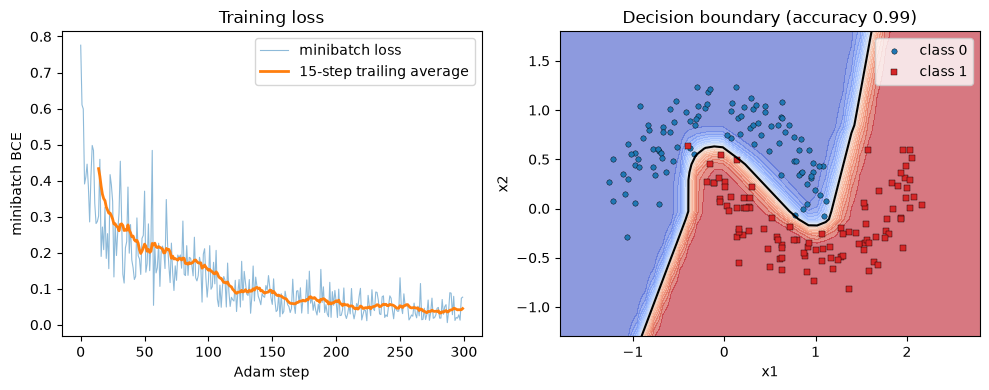

In [23]:
from sklearn.datasets import make_moons

def bce_with_logits(s, y):
    sd = s.data
    out = Value(max(sd, 0.0) + math.log1p(math.exp(-abs(sd))) - y * sd, (s,), "bce")
    p = 1.0 / (1.0 + math.exp(-sd)) if sd >= 0 else math.exp(sd) / (1.0 + math.exp(sd))   # never overflows
    def _backward(g):
        s.grad += (p - y) * g
    out._backward = _backward
    return out

class Neuron:
    def __init__(self, n_in, nonlin=True):
        self.w = [Value(rng.normal(0.0, math.sqrt(2.0 / n_in))) for _ in range(n_in)]
        self.b = Value(0.0)
        self.nonlin = nonlin
    def __call__(self, xs):
        act = self.b
        for wi, xi in zip(self.w, xs):
            act = act + wi * xi
        return act.relu() if self.nonlin else act
    def parameters(self):
        return self.w + [self.b]

class Layer:
    def __init__(self, n_in, n_out, nonlin=True):
        self.neurons = [Neuron(n_in, nonlin) for _ in range(n_out)]
    def __call__(self, xs):
        return [n(xs) for n in self.neurons]
    def parameters(self):
        return [p for n in self.neurons for p in n.parameters()]

class MLP:
    def __init__(self, sizes):
        self.layers = [Layer(sizes[i], sizes[i + 1], nonlin=(i < len(sizes) - 2)) for i in range(len(sizes) - 1)]
    def __call__(self, xs):
        for layer in self.layers:
            xs = layer(xs)
        return xs[0]
    def parameters(self):
        return [p for layer in self.layers for p in layer.parameters()]

X, y = make_moons(n_samples=200, noise=0.15, random_state=0)
model = MLP([2, 16, 1])
params = model.parameters()

def minibatch_loss(idx):
    total = Value(0.0)
    for i in idx:
        total = total + bce_with_logits(model([X[i, 0], X[i, 1]]), float(y[i]))
    return total * (1.0 / len(idx))

def train_accuracy():
    s = np.array([model([a, b]).data for a, b in X])
    return float(np.mean((s > 0) == (y == 1)))

# gradient check before training (on 10 random parameters, one small minibatch)
idx0 = rng.choice(len(X), size=8, replace=False)
for p in params:
    p.grad = 0.0
minibatch_loss(idx0).backward()
g_ana, g_num, h = [], [], 1e-5
for k in rng.choice(len(params), size=10, replace=False):
    p = params[k]; g_ana.append(p.grad); old = p.data
    p.data = old + h; lp = minibatch_loss(idx0).data
    p.data = old - h; lm = minibatch_loss(idx0).data
    p.data = old; g_num.append((lp - lm) / (2 * h))
g_ana, g_num = np.array(g_ana), np.array(g_num)
print(f"gradient check before training: relative error {np.linalg.norm(g_ana - g_num) / (np.linalg.norm(g_ana) + np.linalg.norm(g_num)):.1e}")

# Adam, because plain SGD needs more steps than the scalar engine can afford
lr, beta1, beta2, eps = 0.05, 0.9, 0.999, 1e-8
m = np.zeros(len(params)); v = np.zeros(len(params))
losses = []
for step in range(1, 301):
    idx = rng.choice(len(X), size=32, replace=False)
    loss = minibatch_loss(idx)
    for p in params:
        p.grad = 0.0
    loss.backward()
    g = np.array([p.grad for p in params])
    m = beta1 * m + (1 - beta1) * g
    v = beta2 * v + (1 - beta2) * g ** 2
    update = lr * (m / (1 - beta1 ** step)) / (np.sqrt(v / (1 - beta2 ** step)) + eps)
    for p, u in zip(params, update):
        p.data -= u
    losses.append(loss.data)
    if step % 100 == 0:
        print(f"step {step}: minibatch loss {loss.data:.3f}, train accuracy {train_accuracy():.3f}")

final_acc = train_accuracy()
print(f"final train accuracy: {final_acc:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].plot(losses, lw=0.8, alpha=0.5, label="minibatch loss")
axes[0].plot(np.arange(14, len(losses)), np.convolve(losses, np.ones(15) / 15, mode="valid"), lw=2,
             label="15-step trailing average")             # each average is drawn at the last step it covers
axes[0].set_xlabel("Adam step"); axes[0].set_ylabel("minibatch BCE"); axes[0].set_title("Training loss")
axes[0].legend()
gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 50), np.linspace(-1.3, 1.8, 40))
S = np.array([model([a, b]).data for a, b in zip(gx.ravel(), gy.ravel())]).reshape(gx.shape)
axes[1].contourf(gx, gy, 1 / (1 + np.exp(-S)), levels=20, cmap="coolwarm", alpha=0.6)
axes[1].contour(gx, gy, S, levels=[0.0], colors="k")
for c, mk in ((0, "o"), (1, "s")):
    axes[1].scatter(*X[y == c].T, c=["tab:blue", "tab:red"][c], marker=mk, s=15, edgecolor="k", linewidth=0.3,
                    label=f"class {c}")
axes[1].set_xlabel("x1"); axes[1].set_ylabel("x2"); axes[1].set_title(f"Decision boundary (accuracy {final_acc:.2f})")
axes[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

## Score

In [24]:
summary()


Score: 54/54 checks passed  🎉
